In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [2]:
url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "car_fuel_efficiency_2026.csv"
)

df = pd.read_csv(url)


In [4]:
display(df.head())

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
columns = df.columns.tolist()

In [6]:
print (columns)

['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors', 'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight', 'acceleration', 'fuel_efficiency_mpg']


In [7]:
features = [
    "engine_displacement",
    "horsepower",
    "vehicle_weight",
    "model_year",
]

target = "fuel_efficiency_mpg"

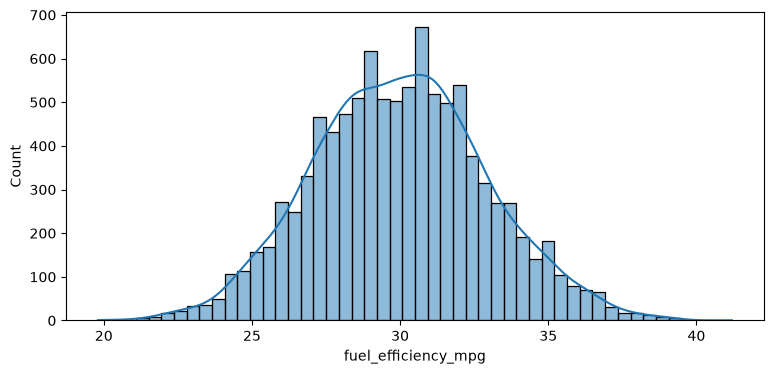

count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

Skewness: 0.08080419601878173


In [9]:
plt.figure(figsize=(9, 4))

sns.histplot(df[target], bins=50, kde=True)

plt.show()

display(df[target].describe())
print("Skewness:", df[target].skew())

In [10]:
missing_values = df.isna().sum()

display(missing_values)

missing_columns = missing_values[missing_values > 0].index.tolist()

print("Columns with missing values:", missing_columns)

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

Columns with missing values: ['horsepower', 'acceleration']


In [11]:
horsepower_median = df["horsepower"].median()

print("Median horsepower:", horsepower_median)

Median horsepower: 254.0


In [12]:
def split_dataset(df, seed):
    n = len(df)

    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)

    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
    df_test = df.iloc[idx[n_train + n_val:]].copy()

    return df_train, df_val, df_test

In [13]:
df_train, df_val, df_test = split_dataset(df, seed=42)

print("Training rows:", len(df_train))
print("Validation rows:", len(df_val))
print("Test rows:", len(df_test))

Training rows: 6000
Validation rows: 2000
Test rows: 2000


In [14]:
def prepare_X(df, fill_value=0):
    return df[features].fillna(fill_value).to_numpy(dtype=float)

In [15]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)

    # First coefficient is the intercept.
    return w_full[0], w_full[1:]

In [16]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [17]:
def rmse(y, y_pred):
    error = y - y_pred
    return np.sqrt(np.mean(error ** 2))

In [18]:
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

horsepower_mean = df_train["horsepower"].mean()

print("Training horsepower mean:", horsepower_mean)

q3_results = []

for method, fill_value in [
    ("With 0", 0),
    ("With mean", horsepower_mean),
]:
    X_train = prepare_X(df_train, fill_value=fill_value)
    X_val = prepare_X(df_val, fill_value=fill_value)

    w0, w = train_linear_regression(X_train, y_train)

    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    q3_results.append({
        "method": method,
        "rmse": score,
        "rmse_rounded": round(score, 3),
    })

q3_results = pd.DataFrame(q3_results)

display(q3_results)

Training horsepower mean: 254.46338337605272


,method,rmse,rmse_rounded
0,With 0,2.205293,2.205
1,With mean,2.201817,2.202


In [19]:
X_train = prepare_X(df_train, fill_value=0)
X_val = prepare_X(df_val, fill_value=0)

y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

q4_results = []

for r in r_values:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    q4_results.append({
        "r": r,
        "rmse": score,
        "rmse_rounded": round(score, 4),
    })

q4_results = pd.DataFrame(q4_results)

display(q4_results)

# Compare rounded scores, then choose the smallest r if tied.
best_result = q4_results.sort_values(
    ["rmse_rounded", "r"]
).iloc[0]

print("Best r:", best_result["r"])

,r,rmse,rmse_rounded
0,0.00,2.205293,2.2053
1,0.01,2.205828,2.2058
2,0.10,2.224143,2.2241
3,1.00,2.349229,2.3492
4,5.00,2.409380,2.4094
5,10.00,2.419470,2.4195
6,100.00,2.429202,2.4292


Best r: 0.0


In [20]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

q5_results = []

for seed in seeds:
    train_seed, val_seed, test_seed = split_dataset(df, seed=seed)

    X_train_seed = prepare_X(train_seed, fill_value=0)
    X_val_seed = prepare_X(val_seed, fill_value=0)

    y_train_seed = train_seed[target].to_numpy()
    y_val_seed = val_seed[target].to_numpy()

    w0, w = train_linear_regression(X_train_seed, y_train_seed)

    y_pred = w0 + X_val_seed.dot(w)
    score = rmse(y_val_seed, y_pred)

    q5_results.append({
        "seed": seed,
        "rmse": score,
    })

q5_results = pd.DataFrame(q5_results)

display(q5_results)

# Use unrounded RMSE values and NumPy's default ddof=0.
std = np.std(q5_results["rmse"].to_numpy())

print("Standard deviation:", std)
print("Rounded standard deviation:", round(std, 3))

,seed,rmse
0,0,2.239204
1,1,2.202113
2,2,2.163420
3,3,2.204359
4,4,2.201880
5,5,2.245785
6,6,2.269721
7,7,2.190795
8,8,2.216611
9,9,2.207037


Standard deviation: 0.028781274078187116
Rounded standard deviation: 0.029


In [21]:
df_train_9, df_val_9, df_test_9 = split_dataset(df, seed=9)

df_full_train = pd.concat(
    [df_train_9, df_val_9],
    ignore_index=True,
)

print("Combined training rows:", len(df_full_train))
print("Test rows:", len(df_test_9))

X_full_train = prepare_X(df_full_train, fill_value=0)
y_full_train = df_full_train[target].to_numpy()

X_test = prepare_X(df_test_9, fill_value=0)
y_test = df_test_9[target].to_numpy()

w0, w = train_linear_regression_reg(
    X_full_train,
    y_full_train,
    r=0.001,
)

y_pred_test = w0 + X_test.dot(w)
test_rmse = rmse(y_test, y_pred_test)

print("Test RMSE:", test_rmse)
print("Rounded test RMSE:", round(test_rmse, 3))

Combined training rows: 8000
Test rows: 2000
Test RMSE: 2.2358277471917636
Rounded test RMSE: 2.236
